# MUST USE PY38 ENV

In [1]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
# from umap import UMAP
import os
import seaborn as sns
import matplotlib
from matplotlib import pyplot as plt
import json

import sys
sys.path.append(r'E:\ZhixiYun\Projects\Neuron_Morphology_Table\Scripts')
from basicfunc import MouseAnatomyTree, bootstrap_stat_test
from sklearn.metrics import normalized_mutual_info_score, adjusted_mutual_info_score, mutual_info_score
import scipy.stats

from sklearn.metrics import pairwise_distances
# import umap
from sklearn.manifold import TSNE
from itertools import product
from sklearn.cluster import SpectralClustering
from sklearn.utils import resample

np.random.seed(821)

In [2]:

lut_human_full_abbr = {
    'Rostral Anterior Cingulate': 'rACC',
    'Posterior Cingulate': 'PCC',
    'Inferior Frontal gyrus': 'IFG',
    'Precentral': 'PrCG',
    'Postcentral': 'PoCG',
    'Superior Parietal': 'SPL',
    'Superior Temporal': 'STG',
    'Middle Temporal': 'MTG',
    'Inferior Temporal': 'ITG',
    'Parahippocampal': 'PHG',
    'Fusiform': 'FuG',
    'Temporal Lobe': 'TL',
    'Cuneus': 'Cun',
    'Cuneus-Lingual': 'Cun-LiG',
    'Transverse Temporal': 'TTG',
    'Middle Frontal gyrus': 'MFG',
    'Supramarginal': 'SMG',
    'TL':'TL','OL':'OL','PL':'PL','FL':'FL','CC':'CC',
    
}


homo_color_lut = {
    # 'OL':np.array([231,172,161])/255.0,
                 'FL':np.array([255,206,72])/255.0,
                 'PL':np.array([153,217,234])/255.0,
                 'TL':np.array([118,137,211])/255.0}

# mouse
color1=np.array([217,85,71])/255.0
# human
color2=np.array([135,207,197])/255.0
# reference dataset
color3=np.array([191,200,215])/255.0

In [ ]:
# homologous/genetic similarity; 3 cases

# df_homo_count = pd.read_csv(r'G:\data\transcriptome\MERFISH\homo_similarity_lobe_yzx.csv',index_col=[0,1])
# df_homo_count = pd.read_csv(r'G:\data\transcriptome\MERFISH\homo_similarity_yzx.csv',index_col=[0,1])
df_homo_count = pd.read_csv(r'G:\data\transcriptome\homo_similarity_yzx.csv',index_col=[0,1])

tmpdict = {'0': 'Glut', '1': 'Glut', '2': 'Glut', '3': 'Glut', '4': 'Glut', '5': 'Gaba',
 '6': 'Gaba', '7': 'Glut', '8': 'Gaba', '9': 'Glut', '10': 'Gaba', '11': 'Glut',
 '12': 'Glut', '13': 'Glut', '14': 'Glut', '15': 'Gaba', '16': 'Glut', '17': 'Glut',
 '18': 'Glut', '19': 'Glut', '20': 'Glut', '21': 'Glut', '22': 'Glut', '23': 'Glut',
 '24': 'Glut', '25': 'Gaba', '26': 'Glut', '27': 'Gaba', '28': 'Gaba', '29': 'Glut',
 '30': 'Gaba', '31': 'Glut', '32': 'Glut', '33': 'Glut', '34': 'Glut'}
# df_homo_count = df_homo_count.iloc[:,np.array(df_homo_count.columns.map(tmpdict)=='Gaba')]
print(df_homo_count.shape)
# df_homo_count = df_homo_count[(df_homo_count.loc['human'].mean()+df_homo_count.loc['mouse'].mean()).sort_values(ascending=False).index]
# df_homo_count.loc[('human','Temporal Lobe'),:] = np.sum(df_homo_count.loc['human'].loc[['Superior Temporal', 'Middle Temporal','Inferior Temporal', 'Parahippocampal','Fusiform','Transverse Temporal']],axis=0)
# df_homo_count=df_homo_count.drop(index=[('human',x) for x in ['Superior Temporal', 'Middle Temporal','Inferior Temporal', 'Parahippocampal','Fusiform','Transverse Temporal']]).sort_index()
len_h_index = df_homo_count.loc['human'].shape[0]
len_m_index = df_homo_count.loc['mouse'].shape[0]

df_homo_count_tmp = df_homo_count.copy()

df_homo_count_tmp = df_homo_count_tmp.div(df_homo_count_tmp.sum(axis=1), axis=0)
# Separate columns based on 'Glut' and 'Gaba'
# glut_columns = df_homo_count_tmp.columns[df_homo_count_tmp.columns.map(tmpdict) == 'Glut']
# gaba_columns = df_homo_count_tmp.columns[df_homo_count_tmp.columns.map(tmpdict) == 'Gaba']
# Normalize 'Glut' columns
# df_homo_count_tmp[glut_columns] = df_homo_count_tmp[glut_columns].div(df_homo_count_tmp[glut_columns].sum(axis=1), axis=0)
# Normalize 'Gaba' columns
# df_homo_count_tmp[gaba_columns] = df_homo_count_tmp[gaba_columns].div(df_homo_count_tmp[gaba_columns].sum(axis=1), axis=0)


df_homo_count_tmp.loc[['human']] = (df_homo_count_tmp.loc[['human']]-df_homo_count_tmp.loc[['human']].mean(axis=0))/df_homo_count_tmp.loc[['human']].std(axis=0)
df_homo_count_tmp.loc[['mouse']] = (df_homo_count_tmp.loc[['mouse']]-df_homo_count_tmp.loc[['mouse']].mean(axis=0))/df_homo_count_tmp.loc[['mouse']].std(axis=0)

pca = PCA(random_state=821)
pca.fit(df_homo_count_tmp.values)
pca_embeddings = pca.transform(df_homo_count_tmp.values)
cumsum = np.cumsum(pca.explained_variance_ratio_)
npc_90 = np.argmax(cumsum >= 0.75) + 1
npc_95 = np.argmax(cumsum >= 0.95) + 1
npc_99 = np.argmax(cumsum >= 0.99) + 1
print(npc_90, npc_95, npc_99)
df_homo_sim_list = []

for n_comp in range(npc_90, npc_99 + 1):
    df_homo_count_tmp_pca = pd.DataFrame(pca_embeddings[:, :n_comp], index=df_homo_count_tmp.index)
    df_homo_sim_list.append(df_homo_count_tmp_pca.T.corr().values)


        
df_homo_sim_list = np.array(df_homo_sim_list)
df_homo_sim = pd.DataFrame(np.mean(df_homo_sim_list,axis=0),index=df_homo_count.index,columns=df_homo_count.index)
df_homo_sim_std = pd.DataFrame(np.std(df_homo_sim_list,axis=0),index=df_homo_count.index,columns=df_homo_count.index)

df_homo_rank_row_list = np.array([np.argsort(x, axis=1)[::-1] for x in df_homo_sim_list[:,:len_h_index,len_h_index:]])*len_h_index/len_m_index
df_homo_rank_col_list = np.array([np.argsort(x, axis=0)[::-1] for x in df_homo_sim_list[:,:len_h_index,len_h_index:]])
df_homo_rank_row = pd.DataFrame(np.mean(df_homo_rank_row_list, axis=0),index=df_homo_count.index[:len_h_index],columns=df_homo_count.index[len_h_index:])
df_homo_rank_col = pd.DataFrame(np.mean(df_homo_rank_col_list, axis=0),index=df_homo_count.index[:len_h_index],columns=df_homo_count.index[len_h_index:])
df_homo_rank_row_std = pd.DataFrame(np.std(df_homo_rank_row_list, axis=0),index=df_homo_count.index[:len_h_index],columns=df_homo_count.index[len_h_index:])
df_homo_rank_col_std = pd.DataFrame(np.std(df_homo_rank_col_list, axis=0),index=df_homo_count.index[:len_h_index],columns=df_homo_count.index[len_h_index:])



(26, 37)
6 13 19


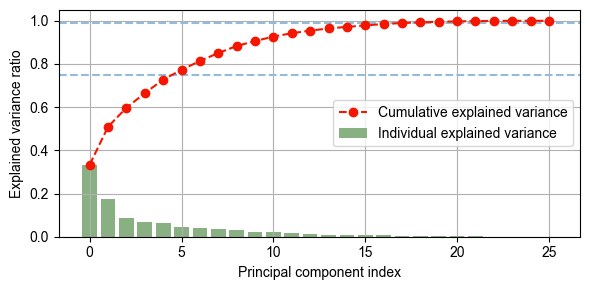

In [12]:
exp_var_pca = pca.explained_variance_ratio_
#
# Cumulative sum of eigenvalues; This will be used to create step plot
# for visualizing the variance explained by each principal component.
#
cum_sum_eigenvalues = np.cumsum(exp_var_pca)
#
# Create the visualization plot
#
plt.figure(figsize=(6,3))
plt.axhline(y=0.75,ls='--',color=np.array([146,188,218])/255)
plt.axhline(y=0.99,ls='--',color=np.array([146,188,218])/255)
plt.bar(range(0,len(exp_var_pca)), exp_var_pca, alpha=1, align='center', label='Individual explained variance',color=np.array([137,176,131])/255.0)
# plt.step(range(0,len(cum_sum_eigenvalues)), cum_sum_eigenvalues, where='mid',label='Cumulative explained variance',color=np.array([245,22,0])/255.0)
plt.plot(range(0,len(cum_sum_eigenvalues)), cum_sum_eigenvalues, marker='o', linestyle='--', color=np.array([245,22,0])/255.0, label='Cumulative explained variance')
plt.ylabel('Explained variance ratio')
plt.xlabel('Principal component index')

plt.legend(loc='center right')
plt.grid()
plt.tight_layout()
# plt.savefig(rf'E:\ZhixiYun\Projects\fMOST_atlas\Figures\Homologous\gene\PCA_evr.png', bbox_inches='tight', dpi=500)
plt.show()

d:\anaconda3\envs\py38\lib\site-packages\seaborn\matrix.py:1124: UserWarning: ``square=True`` ignored in clustermap
  warnings.warn(msg)


<Figure size 640x480 with 0 Axes>

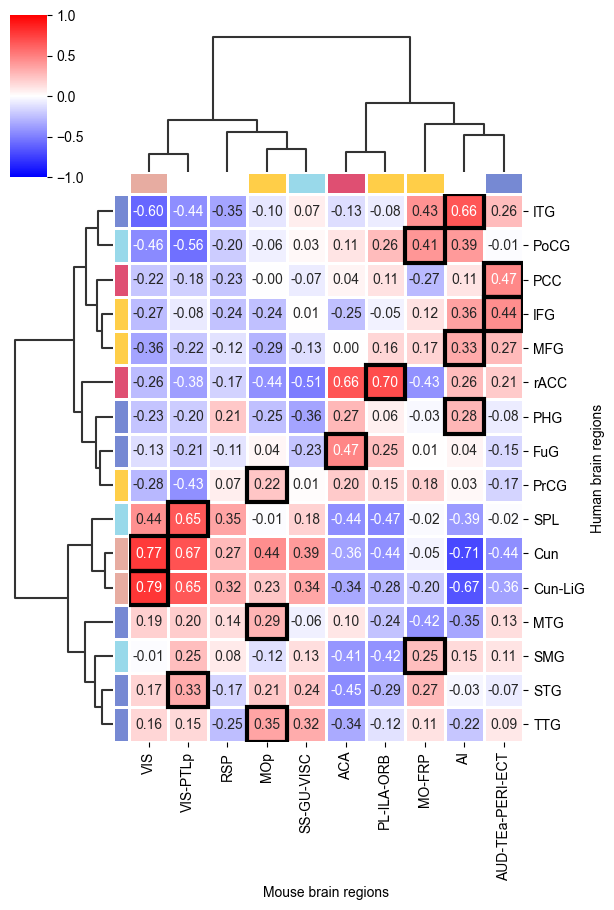

d:\anaconda3\envs\py38\lib\site-packages\seaborn\matrix.py:1124: UserWarning: ``square=True`` ignored in clustermap
  warnings.warn(msg)


<Figure size 640x480 with 0 Axes>

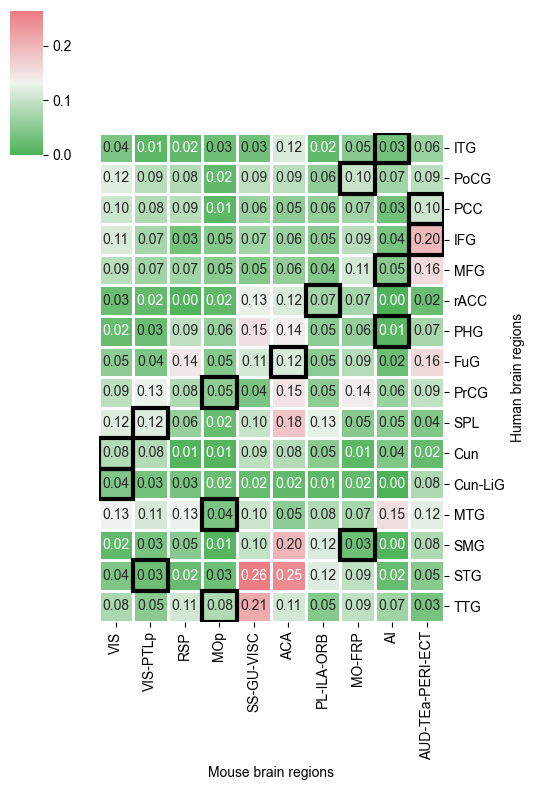

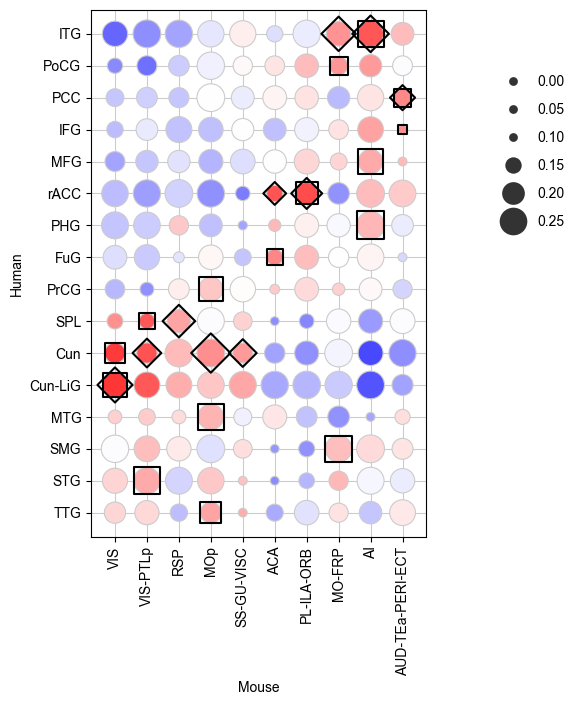

In [15]:
lut_region2lobe = {
    'Cuneus':'OL', 'Cuneus-Lingual':'OL', 'Fusiform':'TL', 'Inferior Frontal gyrus':'FL',
    'Inferior Temporal':'TL', 'Middle Frontal gyrus':'FL', 'Middle Temporal':'TL',
    'Parahippocampal':'TL', 'Postcentral':'PL', 'Posterior Cingulate':'CC', 'Precentral':'FL',
    'Rostral Anterior Cingulate':'CC', 'Superior Parietal':'PL', 'Superior Temporal':'TL',
    'Supramarginal':'PL', 'Transverse Temporal':'TL','Temporal Lobe':'TL',
    'TL':'TL','OL':'OL','PL':'PL','FL':'FL','CC':'CC',
}
lut_region2lobe_m = {
    'MOp': 'FL', 'MOs': 'FL', 'ORB': 'FL', 'FRP': 'FL',
    'SSp': 'PL', 'SSs': 'PL', 'PTLp': 'PL', 'VISC': 'PL',
    'AUDp': 'TL', 'AUDd': 'TL', 'AUDv': 'TL', 'AUDpo': 'TL',
    'PERI': 'TL', 'TEa': 'TL', 'ECT': 'TL', 'VISpor': 'TL',
    'AUD': 'TL', 'VIS': 'OL', 
    'ACA': 'CC', 'ILA': 'FL', 'PL': 'FL', 'GU': 'PL', 
    # 'AI': 'FL', 'RSP': 'PL'
    'AUD-TEa-PERI-ECT': 'TL', 'MO-FRP': 'FL', 'PL-ILA-ORB': 'FL',
    'SS-GU-VISC': 'PL',
}
tmp_homo_color_lut = {
    'OL':np.array([231,172,161])/255.0,
     'FL':np.array([255,206,72])/255.0,
     'PL':np.array([153,217,234])/255.0,
     'TL':np.array([118,137,211])/255.0,
    'CC':np.array([223,79,114])/255.0}

plt.figure()
tmpdf1 = df_homo_sim.iloc[:len_h_index,len_h_index:].copy().loc['human','mouse']
tmpdf1.index.name = 'Human brain regions'
tmpdf1.columns.name = 'Mouse brain regions'
g1=sns.clustermap(tmpdf1, square=True, annot=True, fmt='.2f', cmap='bwr', 
                  figsize=(9 * (len(tmpdf1.columns) + 3) / len_h_index, 9), method='ward',
                  center=0,vmin=-1,vmax=1,
                  tree_kws=dict(linewidths=1.5),
                  row_colors=tmpdf1.index.map(lut_region2lobe).map(tmp_homo_color_lut),
                  col_colors=tmpdf1.columns.map(lut_region2lobe_m).map(tmp_homo_color_lut).fillna('#FFFFFF'),
                  row_cluster=True, col_cluster=True, lw=1, cbar_pos=(0.02, 0.82, 0.05, 0.18),)
# g1.cax.set_visible(False)
g1.ax_heatmap.set_yticklabels([lut_human_full_abbr[x.get_text()] for x in g1.ax_heatmap.get_yticklabels()])
for i in range(tmpdf1.shape[0]):
    idx1 = np.argsort(tmpdf1.values[i])[::-1][0]
    g1.ax_heatmap.add_patch(plt.Rectangle((np.argwhere(np.array(g1.dendrogram_col.reordered_ind)==idx1).flatten()[0],
                                          np.argwhere(np.array(g1.dendrogram_row.reordered_ind)==i).flatten()[0]),
                                          1,1,fill=False,lw=3,color='black',))
# tmpdf1.to_csv(rf'E:\ZhixiYun\Projects\fMOST_atlas\Figures\Homologous\gene\MERFISH\PCC_mean_260325.csv')
# plt.savefig(rf'E:\ZhixiYun\Projects\fMOST_atlas\Figures\Homologous\gene\PCC_mean.svg', bbox_inches='tight', dpi=500)
plt.show()

plt.figure()
tmpdf2 = df_homo_sim_std.iloc[:len_h_index,len_h_index:].copy().loc['human','mouse']
tmpdf2.index.name = 'Human brain regions'
tmpdf2.columns.name = 'Mouse brain regions'
tmpdf2 = np.max(tmpdf2)-tmpdf2
g2=sns.clustermap(np.max(tmpdf2)-tmpdf2.iloc[g1.dendrogram_row.reordered_ind,g1.dendrogram_col.reordered_ind],square=True,annot=True,fmt='.2f', 
                  cmap=sns.diverging_palette(h_neg=130, h_pos=10, s=75, l=65, sep=3,n=255), 
                  figsize=(8 * (len(tmpdf1.columns) + 3) / len_h_index, 8), method='ward',
                 # center=0,vmin=-0.5,vmax=1,
                 row_cluster=False, col_cluster=False,lw=1)
# g2.cax.set_visible(False)
g2.ax_heatmap.set_yticklabels([lut_human_full_abbr[x.get_text()] for x in g2.ax_heatmap.get_yticklabels()])
for i in range(tmpdf2.shape[0]):
    idx1 = np.argsort(tmpdf1.values[i])[::-1][0]
    g2.ax_heatmap.add_patch(plt.Rectangle((np.argwhere(np.array(g1.dendrogram_col.reordered_ind)==idx1).flatten()[0],
                                          np.argwhere(np.array(g1.dendrogram_row.reordered_ind)==i).flatten()[0]),
                                          1,1,fill=False,lw=3,color='black',))
# plt.savefig(rf'E:\ZhixiYun\Projects\fMOST_atlas\Figures\Homologous\gene\PCC_std.svg', bbox_inches='tight', dpi=500)
plt.show()


df_relplot = pd.DataFrame([tmpdf1.values[g1.dendrogram_row.reordered_ind][:,g1.dendrogram_col.reordered_ind].flatten(),
                           tmpdf2.values[g1.dendrogram_row.reordered_ind][:,g1.dendrogram_col.reordered_ind].flatten()],
                          index=['mean','std'],).T
df_relplot[['human','mouse']] = [[x,y] for x in range(len(tmpdf1.index)) for y in range(len(tmpdf1.columns))]

size_norm = np.percentile(tmpdf2.values.flatten(),(5,95))
# # MERFISH
# height = 3
# aspect = (len(tmpdf1.columns)+0)/len_h_index
# others
height = 6
aspect = (len(tmpdf1.columns)+1)/len_h_index
g3=sns.relplot(data=df_relplot, y='human', x='mouse', hue='mean', size='std',
               palette='bwr', hue_norm=(-1,1), edgecolor='.8',
               height=height, aspect=aspect, sizes=(40,400), legend='auto',
               size_norm=tuple(size_norm),
               zorder=11,)

for i in range(tmpdf1.shape[0]):
    adjust_idx = np.argmax(tmpdf1.values[g1.dendrogram_row.reordered_ind][:,g1.dendrogram_col.reordered_ind][i])
    tmp_std = tmpdf2.values[g1.dendrogram_row.reordered_ind][:,g1.dendrogram_col.reordered_ind][i][adjust_idx]
    g3.ax.scatter(adjust_idx,i,
                  s=40+(400-40)*np.clip((tmp_std-size_norm[0])/(size_norm[1]-size_norm[0]),0,1), 
                  facecolors='none', edgecolors='black',lw=1.5,zorder=12,marker='s')
    
for i in range(tmpdf1.shape[1]):
    adjust_idx = np.argmax(tmpdf1.values[g1.dendrogram_row.reordered_ind][:,g1.dendrogram_col.reordered_ind][:,i])
    tmp_std = tmpdf2.values[g1.dendrogram_row.reordered_ind][:,g1.dendrogram_col.reordered_ind][:,i][adjust_idx]
    g3.ax.scatter(i,adjust_idx,
                  s=40+(400-40)*np.clip((tmp_std-size_norm[0])/(size_norm[1]-size_norm[0]),0,1), 
                  facecolors='none', edgecolors='black',lw=1.5,zorder=12,marker='D')

g3.ax.tick_params('x', rotation=90)
g3.ax.invert_yaxis()
g3.ax.set_xlim((np.modf(g3.ax.get_xlim()[0])[1]-np.modf(g3.ax.get_ylim()[0])[0],np.modf(g3.ax.get_xlim()[1])[1]+np.modf(g3.ax.get_ylim()[0])[0]))

g3.ax.spines['top'].set_visible(True)
g3.ax.spines['right'].set_visible(True)
g3.ax.grid(ls='-',color='.8')
g3.ax.set_xticks(np.arange(tmpdf1.shape[1]))
g3.ax.set_yticks(np.arange(tmpdf1.shape[0]))
g3.ax.set_xticklabels(tmpdf1.columns[g1.dendrogram_col.reordered_ind])
g3.ax.set_yticklabels([lut_human_full_abbr[x] for x in tmpdf1.index[g1.dendrogram_row.reordered_ind]])
g3.ax.set_xlabel('Mouse brain regions')
g3.ax.set_ylabel('Human brain regions')

handles, labels = g3.ax.get_legend_handles_labels()
g3._legend.remove()
g3.ax.legend(handles=handles[labels.index('std')+1:], labels=labels[labels.index('std')+1:], loc='upper right', 
             bbox_to_anchor=(1.25, 0.9), frameon=False, labelspacing=1.0)


# # merfish lobe level
# g3.ax.set_xlim(-0.6,3.6)
# g3.ax.set_ylim(3.6, -0.6)
# handles, labels = g3.ax.get_legend_handles_labels()
# g3.tick_params("x", rotation=0)


# g3._legend.remove()
g3.ax.legend(handles=handles[labels.index('std')+1:], labels=labels[labels.index('std')+1:], loc='upper right', 
             bbox_to_anchor=(1.45, 0.9), frameon=False, labelspacing=1.0)
g3.ax.set_xlabel('Mouse')
g3.ax.set_ylabel('Human')

# plt.savefig(rf'E:\ZhixiYun\Projects\fMOST_atlas\Figures\Homologous\gene\MERFISH\PCC_relplot_mean_std.svg', bbox_inches='tight', dpi=500)
# plt.savefig(rf'E:\ZhixiYun\Projects\fMOST_atlas\Figures\Homologous\gene\MERFISH\PCC_relplot_mean_std_MERFISH_LOBE.svg', bbox_inches='tight', dpi=500)
plt.show()

In [ ]:
tmpdf1_long = tmpdf1.stack().reset_index()
tmpdf1_long.columns = ['Human brain regions', 'Mouse brain regions', 'value']
tmpdf1_long['stat'] = 'mean'

tmpdf2_long = tmpdf2.stack().reset_index()
tmpdf2_long.columns = ['Human brain regions', 'Mouse brain regions', 'value']
tmpdf2_long['stat'] = 'std'

df_sourcedata = pd.concat([tmpdf1_long, tmpdf2_long], ignore_index=True)
df_sourcedata = df_sourcedata[['Human brain regions', 'Mouse brain regions', 'stat', 'value']]

# df_sourcedata.to_csv(rf'E:\ZhixiYun\Projects\fMOST_atlas\Tables\source_data\EDF_Fig4C_scRNA.csv', index=False)
df_sourcedata

,Human brain regions,Mouse brain regions,stat,value
0,Cuneus,ACA,mean,-0.360903
1,Cuneus,AI,mean,-0.714690
2,Cuneus,AUD-TEa-PERI-ECT,mean,-0.437832
3,Cuneus,MO-FRP,mean,-0.045552
4,Cuneus,MOp,mean,0.440976
...,...,...,...,...
315,Transverse Temporal,PL-ILA-ORB,std,0.217198
316,Transverse Temporal,RSP,std,0.156316
317,Transverse Temporal,SS-GU-VISC,std,0.051708
318,Transverse Temporal,VIS,std,0.187296
